# Spectral-Normalized ResNet GAN on MNIST

This notebook carries the ring GAN sequence into MNIST with a robust unconditional **ResNet GAN** and techniques that demonstrate modern adversarial modeling:

- residual upsampling and downsampling blocks;
- spectral normalization in the discriminator;
- hinge adversarial losses;
- exponential moving average (EMA) generator weights;
- differentiable augmentation;
- fixed-sample evolution, diversity, and memorization diagnostics.

### Learning goals
1. Understand practical architectural asymmetry between generator and discriminator.
2. Stabilize adversarial optimization without turning the model into a likelihood model.
3. Demonstrate fast, sharp one-pass generation.
4. Diagnose mode collapse and memorization explicitly.
5. Contrast sample quality with the absence of normalized density evaluation.

> **Execution note:** Representative outputs are embedded below. **Run modes:** `RUN_MODE = "lecture"` (the default) loads the bundled checkpoint and avoids retraining. Use `"full"` to train the documented configuration, or `"smoke"` for a reduced CPU pipeline check. Smoke-mode checkpoints and results are deliberately separate and are **not** representative model results.

## Before you begin

**Prerequisites.** Be comfortable with minimax/adversarial training, backpropagation through two networks, convolutional residual blocks, and sample-based evaluation. Notebook 04 (the ring GAN) is the conceptual predecessor.

> **Notation and orientation**
> - $z\sim p(z)$, $G(z)$ is a generated image, $D(x)$ is a real-valued critic score, and $G_{\mathrm{EMA}}$ is the exponential-moving-average generator.
> - **Unchanged from the ring:** the two-player game, implicit density, and risk of mode dropping.
> - **New at image scale:** residual convolutions, spectral normalization, augmentation, and class/feature diagnostics for coverage and memorization.

## 1. Setup and configuration

In [1]:
import copy
import gzip
import math
import random
import struct
import time
from contextlib import contextmanager
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.nn.utils.parametrizations import spectral_norm
from torch.utils.data import DataLoader, TensorDataset

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"

RUN_MODE = "lecture"  # "lecture", "full", or "smoke"
if RUN_MODE not in {"lecture", "full", "smoke"}:
    raise ValueError("RUN_MODE must be 'lecture', 'full', or 'smoke'.")
TRAIN = RUN_MODE != "lecture"
EPOCHS = 1 if RUN_MODE == "smoke" else 60
BATCH_SIZE = 128
LATENT_DIM = 128
BASE_CHANNELS = 32 if RUN_MODE == "smoke" else 128
G_LR = 2e-4
D_LR = 2e-4
N_CRITIC = 2
EMA_DECAY = 0.999
NOTEBOOK_DIR = Path("notebooks") if Path("notebooks").is_dir() else Path(".")
checkpoint_name = "resnet_gan_mnist_smoke.pt" if RUN_MODE == "smoke" else "resnet_gan_mnist.pt"
CHECKPOINT = NOTEBOOK_DIR / "checkpoints" / checkpoint_name
CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)
PLOT_THEME = "light"  # Change to "dark" for the dark plot palette.
if PLOT_THEME not in {"light", "dark"}:
    raise ValueError("PLOT_THEME must be 'light' or 'dark'.")

# Start from Matplotlib defaults so light mode keeps the standard coloring.
plt.style.use("default")
if PLOT_THEME == "dark":
    plt.style.use("dark_background")
    plt.rcParams.update(
        {
            "figure.facecolor": "#0a0f18",
            "figure.edgecolor": "#0a0f18",
            "axes.facecolor": "#111926",
            "axes.edgecolor": "#e8eff9",
            "axes.labelcolor": "#e8eff9",
            "axes.titlecolor": "#e8eff9",
            "text.color": "#e8eff9",
            "xtick.color": "#e8eff9",
            "ytick.color": "#e8eff9",
            "grid.color": "#2b3340",
            "savefig.facecolor": "#0a0f18",
            "savefig.edgecolor": "#0a0f18",
        }
    )

PLOT_REFERENCE_COLOR = "black" if PLOT_THEME == "light" else "#6cd2e8"
PLOT_GENERATED_COLOR = "tab:orange" if PLOT_THEME == "light" else "#f09a4b"
PLOT_GUIDE_COLOR = "black" if PLOT_THEME == "light" else "#e8eff9"

plt.rcParams.update({"figure.figsize": (7, 5), "axes.grid": False, "font.size": 11})
print(f"PyTorch {torch.__version__} | device: {DEVICE} | run mode: {RUN_MODE}")
if RUN_MODE == "smoke":
    print("SMOKE MODE: reduced-cost pipeline check; results are not representative.")

PyTorch 2.12.0+cu130 | device: cuda | run mode: lecture


## 2. Data preprocessing

Real images are scaled to $[-1,1]$ to match the generator's `tanh` output. Labels are never provided to the GAN. They are used only by an evaluation classifier after training.

In [2]:
DATA_DIR = NOTEBOOK_DIR / "data/mnist"
DATA_DIR.mkdir(parents=True, exist_ok=True)
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"
FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}
for filename in FILES.values():
    destination = DATA_DIR / filename
    if not destination.exists():
        urlretrieve(BASE_URL + filename, destination)


def read_images(path):
    with gzip.open(path, "rb") as f:
        magic, n, h, w = struct.unpack(">IIII", f.read(16))
        assert magic == 2051
        data = np.frombuffer(f.read(), dtype=np.uint8).copy()
    return torch.from_numpy(data.reshape(n, 1, h, w)).float() / 255


def read_labels(path):
    with gzip.open(path, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        assert magic == 2049
        data = np.frombuffer(f.read(), dtype=np.uint8).copy()
    return torch.from_numpy(data.astype(np.int64))


x_train = read_images(DATA_DIR / FILES["train_images"])
y_train = read_labels(DATA_DIR / FILES["train_labels"])
x_test = read_images(DATA_DIR / FILES["test_images"])
y_test = read_labels(DATA_DIR / FILES["test_labels"])
train_count = len(x_train) if RUN_MODE != "smoke" else min(2_048, len(x_train))
train_dataset = TensorDataset(
    x_train[:train_count] * 2 - 1, y_train[:train_count]
)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    pin_memory=PIN_MEMORY,
    generator=torch.Generator().manual_seed(SEED),
)
print(tuple(x_train.shape))

(60000, 1, 28, 28)


In [3]:
def show_image_grid(images, nrow=10, title=None, value_range=(0, 1)):
    images = images.detach().cpu()
    images = images[:, 0] if images.ndim == 4 else images
    ncol = int(np.ceil(len(images) / nrow))
    canvas = torch.ones(ncol * 28 + ncol - 1, nrow * 28 + nrow - 1)
    for i, image in enumerate(images):
        row, col = divmod(i, nrow)
        canvas[row * 29 : row * 29 + 28, col * 29 : col * 29 + 28] = image
    fig, ax = plt.subplots(figsize=(nrow, ncol))
    ax.imshow(canvas, cmap="gray", vmin=value_range[0], vmax=value_range[1])
    ax.axis("off")
    if title:
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

## 3. Residual generator and spectral-normalized discriminator

The generator uses residual upsampling blocks. The discriminator uses residual downsampling and **spectral normalization**, constraining each layer's operator norm and controlling discriminator sensitivity.

Batch normalization appears only in the generator. The discriminator remains deterministic apart from data augmentation, making its Lipschitz control easier to interpret.

In [4]:
class GBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.norm1 = nn.BatchNorm2d(in_channels)
        self.norm2 = nn.BatchNorm2d(out_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = nn.Conv2d(in_channels, out_channels, 1)

    def forward(self, x):
        residual = F.interpolate(x, scale_factor=2, mode="nearest")
        residual = self.skip(residual)
        h = F.relu(self.norm1(x))
        h = F.interpolate(h, scale_factor=2, mode="nearest")
        h = self.conv1(h)
        h = self.conv2(F.relu(self.norm2(h)))
        return h + residual


class Generator(nn.Module):
    def __init__(self, base=128):
        super().__init__()
        self.project = nn.Linear(LATENT_DIM, base * 2 * 7 * 7)
        self.block1 = GBlock(base * 2, base)
        self.block2 = GBlock(base, base // 2)
        self.norm = nn.BatchNorm2d(base // 2)
        self.output = nn.Conv2d(base // 2, 1, 3, padding=1)

    def forward(self, z):
        h = self.project(z).reshape(-1, BASE_CHANNELS * 2, 7, 7)
        h = self.block1(h)
        h = self.block2(h)
        return torch.tanh(self.output(F.relu(self.norm(h))))


class DBlock(nn.Module):
    def __init__(self, in_channels, out_channels, downsample=True, first=False):
        super().__init__()
        self.downsample = downsample
        self.first = first
        self.conv1 = spectral_norm(nn.Conv2d(in_channels, out_channels, 3, padding=1))
        self.conv2 = spectral_norm(nn.Conv2d(out_channels, out_channels, 3, padding=1))
        self.skip = spectral_norm(nn.Conv2d(in_channels, out_channels, 1))

    def forward(self, x):
        residual = self.skip(x)
        residual = F.avg_pool2d(residual, 2) if self.downsample else residual
        h = x if self.first else F.relu(x)
        h = self.conv1(h)
        h = self.conv2(F.relu(h))
        h = F.avg_pool2d(h, 2) if self.downsample else h
        return h + residual


class Discriminator(nn.Module):
    def __init__(self, base=128):
        super().__init__()
        self.blocks = nn.Sequential(
            DBlock(1, base // 2, True, True),
            DBlock(base // 2, base, True),
            DBlock(base, base * 2, False),
            DBlock(base * 2, base * 2, False),
        )
        self.output = spectral_norm(nn.Linear(base * 2, 1))

    def forward(self, x):
        h = F.relu(self.blocks(x)).sum((2, 3))
        return self.output(h).squeeze(1)


def initialize(module):
    if isinstance(module, (nn.Conv2d, nn.Linear)):
        weight = (
            module.parametrizations.weight.original
            if hasattr(module, "parametrizations")
            and hasattr(module.parametrizations, "weight")
            else module.weight
        )
        nn.init.orthogonal_(weight)
        if module.bias is not None:
            nn.init.zeros_(module.bias)


G = Generator(BASE_CHANNELS).to(DEVICE)
D = Discriminator(BASE_CHANNELS).to(DEVICE)
G.apply(initialize)
D.apply(initialize)
G_ema = copy.deepcopy(G).eval().requires_grad_(False)
print(
    f"G: {sum(p.numel() for p in G.parameters()):,} | D: {sum(p.numel() for p in D.parameters()):,}"
)

G: 2,214,529 | D: 2,431,937


## 4. Hinge loss and differentiable augmentation

Hinge losses are common in modern image GANs:

$$L_D=\mathbb E[\max(0,1-D(x))]+\mathbb E[\max(0,1+D(G(z)))],$$
$$L_G=-\mathbb E[D(G(z))].$$

Small differentiable translations and brightness changes regularize the discriminator without changing the generator's differentiability. EMA generator parameters reduce visible oscillation and are used for all final samples.

In [5]:
def augment(x):
    if not G.training:
        return x
    # Per-image brightness and integer translation; differentiable w.r.t. pixels.
    brightness = 0.1 * torch.randn(len(x), 1, 1, 1, device=x.device)
    x = (x + brightness).clamp(-1, 1)
    pad = 2
    x = F.pad(x, (pad, pad, pad, pad), mode="reflect")
    offsets = torch.randint(0, 2 * pad + 1, (len(x), 2), device=x.device)
    return torch.stack(
        [
            x[
                i,
                :,
                offsets[i, 0] : offsets[i, 0] + 28,
                offsets[i, 1] : offsets[i, 1] + 28,
            ]
            for i in range(len(x))
        ]
    )


def d_loss(real_score, fake_score):
    return F.relu(1 - real_score).mean() + F.relu(1 + fake_score).mean()


def g_loss(fake_score):
    return -fake_score.mean()


@torch.no_grad()
def update_ema(target, source, decay):
    for target_parameter, source_parameter in zip(
        target.parameters(), source.parameters()
    ):
        target_parameter.lerp_(source_parameter, 1 - decay)
    for target_buffer, source_buffer in zip(target.buffers(), source.buffers()):
        target_buffer.copy_(source_buffer)


z = torch.randn(8, LATENT_DIM, device=DEVICE)
fake = G(z)
assert fake.shape == (8, 1, 28, 28) and torch.isfinite(
    d_loss(D(fake), D(fake)) + g_loss(D(fake))
)
print("Shape and loss sanity checks passed")

Shape and loss sanity checks passed


## 5. Train the adversarial game

The discriminator receives `N_CRITIC` updates per generator update. Fixed EMA samples are saved at regular intervals. Checkpoints preserve both live and EMA generators.

In [6]:
opt_G = torch.optim.Adam(G.parameters(), lr=G_LR, betas=(0.0, 0.9))
opt_D = torch.optim.Adam(D.parameters(), lr=D_LR, betas=(0.0, 0.9))
history = {key: [] for key in ["G", "D", "D_real", "D_fake"]}
fixed_z = torch.randn(100, LATENT_DIM, device=DEVICE)
snapshots = {}

if not TRAIN:
    checkpoint = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)
    G.load_state_dict(checkpoint["G"])
    G_ema.load_state_dict(checkpoint["G_ema"])
    D.load_state_dict(checkpoint["D"])
    history = checkpoint["history"]
    print(f"Loaded {CHECKPOINT}")
else:
    for epoch in range(1, EPOCHS + 1):
        G.train()
        D.train()
        totals = np.zeros(4)
        count = 0
        for real, _ in train_loader:
            real = real.to(DEVICE, non_blocking=True)
            n = len(real)
            for _ in range(N_CRITIC):
                opt_D.zero_grad(set_to_none=True)
                with torch.no_grad():
                    fake = G(torch.randn(n, LATENT_DIM, device=DEVICE))
                real_score = D(augment(real))
                fake_score = D(augment(fake))
                loss_D = d_loss(real_score, fake_score)
                loss_D.backward()
                opt_D.step()
            opt_G.zero_grad(set_to_none=True)
            fake = G(torch.randn(n, LATENT_DIM, device=DEVICE))
            fake_score_G = D(augment(fake))
            loss_G = g_loss(fake_score_G)
            loss_G.backward()
            opt_G.step()
            update_ema(G_ema, G, EMA_DECAY)
            totals += np.array(
                [
                    loss_G.item(),
                    loss_D.item(),
                    real_score.mean().item(),
                    fake_score.mean().item(),
                ]
            )
            count += 1
        averages = totals / count
        for key, value in zip(history, averages):
            history[key].append(value)
        if epoch == 1 or epoch % 5 == 0:
            G_ema.eval()
            with torch.no_grad():
                snapshots[epoch] = ((G_ema(fixed_z) + 1) / 2).cpu()
            print(
                f"epoch {epoch:3d}/{EPOCHS} | D {averages[1]:.3f} | G {averages[0]:.3f} | D(real) {averages[2]:.3f} | D(fake) {averages[3]:.3f}"
            )
        torch.save(
            {
                "G": G.state_dict(),
                "G_ema": G_ema.state_dict(),
                "D": D.state_dict(),
                "history": history,
                "epoch": epoch,
            },
            CHECKPOINT,
        )

Loaded checkpoints/resnet_gan_mnist.pt


## 6. Training dynamics and fixed samples

GAN losses are game diagnostics, not sample-quality metrics. The same fixed latent vectors reveal whether image quality and diversity improve or collapse over time.

### Predict before running

> **Commit to a prediction:** will smoothly decreasing generator and discriminator losses be sufficient evidence of successful GAN training? Predict what the fixed-sample and diversity traces may reveal, and justify why the game differs from ordinary loss minimization.

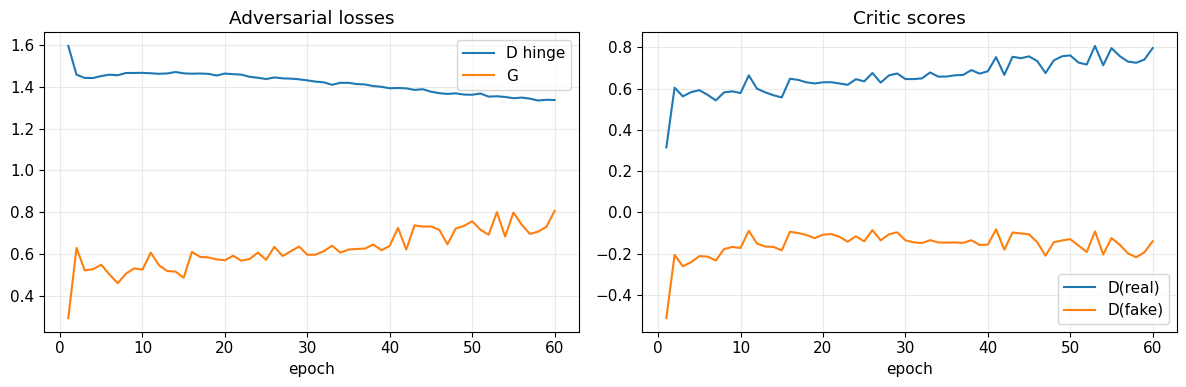

In [7]:
epochs = np.arange(1, len(history["G"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["D"], label="D hinge")
axes[0].plot(epochs, history["G"], label="G")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[0].set(xlabel="epoch", title="Adversarial losses")
axes[1].plot(epochs, history["D_real"], label="D(real)")
axes[1].plot(epochs, history["D_fake"], label="D(fake)")
axes[1].legend()
axes[1].grid(alpha=0.25)
axes[1].set(xlabel="epoch", title="Critic scores")
plt.tight_layout()
plt.show()
for epoch, images in snapshots.items():
    show_image_grid(images[:50], 10, f"EMA fixed samples, epoch {epoch}")

>**Expected observation / interpretation.** Adversarial losses may oscillate or stabilize without tracking visual quality monotonically. Fixed samples can improve while diversity falls, so training dynamics must be read together with images and coverage diagnostics.

## 7. Fast unconditional generation and interpolation

EMA weights generate final samples in one parallel forward pass. Spherical interpolation tests whether latent neighborhoods map to smooth semantic transitions.

100 samples: 0.0183 s


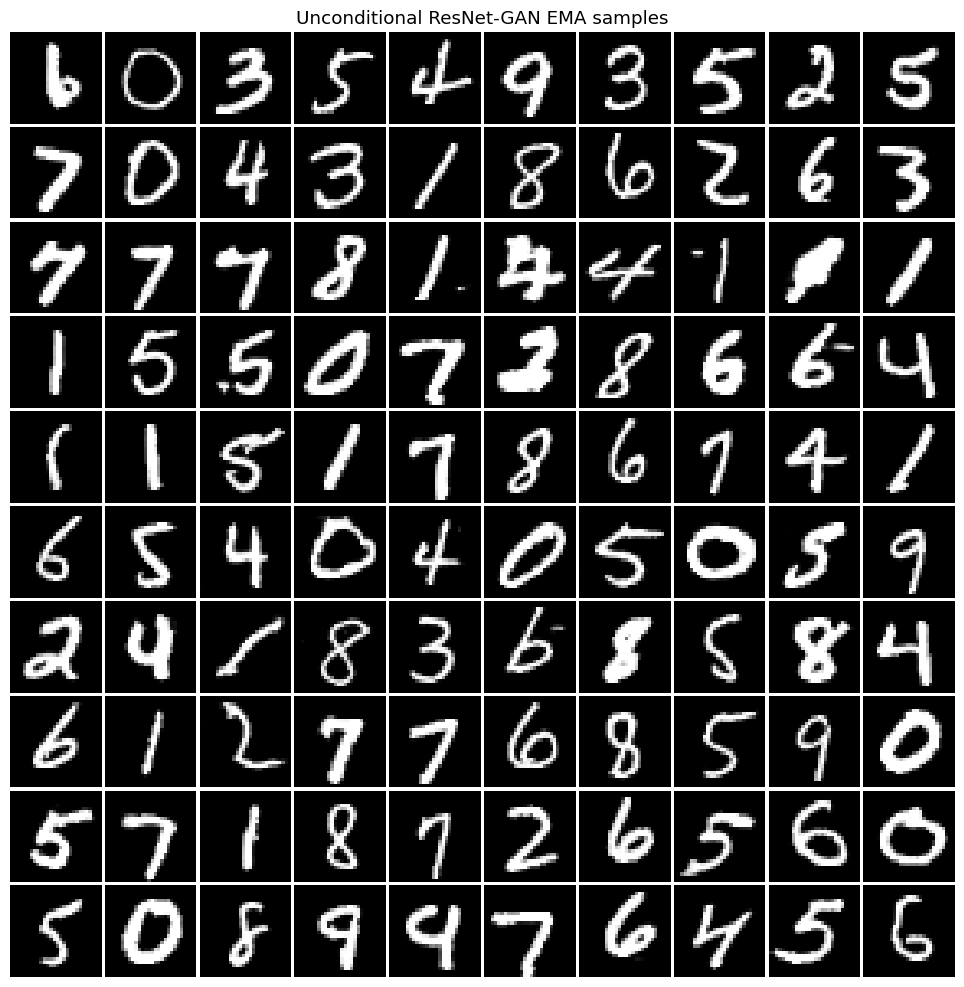

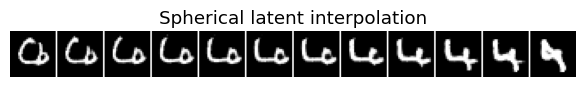

In [8]:
G_ema.eval()
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
start = time.perf_counter()
with torch.no_grad():
    samples = ((G_ema(torch.randn(100, LATENT_DIM, device=DEVICE)) + 1) / 2).cpu()
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
print(f"100 samples: {time.perf_counter()-start:.4f} s")
show_image_grid(samples, 10, "Unconditional ResNet-GAN EMA samples")


def slerp(a, b, weights):
    ua, ub = F.normalize(a, dim=0), F.normalize(b, dim=0)
    angle = torch.acos(torch.clamp(torch.dot(ua, ub), -1 + 1e-6, 1 - 1e-6))
    den = torch.sin(angle)
    return torch.stack(
        [
            torch.sin((1 - w) * angle) / den * a + torch.sin(w * angle) / den * b
            for w in weights
        ]
    )


z0, z1 = torch.randn(2, LATENT_DIM, device=DEVICE)
path = slerp(z0, z1, torch.linspace(0, 1, 12, device=DEVICE))
with torch.no_grad():
    interpolation = ((G_ema(path) + 1) / 2).cpu()
show_image_grid(interpolation, 12, "Spherical latent interpolation")

## 8. Evaluation probe: class coverage and confidence

A separately trained classifier is not part of the GAN. It approximates class coverage, histogram entropy, and recognizability. Visual inspection and nearest-neighbor checks remain necessary because classifiers can be fooled.

In [9]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 10),
        )

    def forward(self, x):
        return self.net(x)


classifier = Classifier().to(DEVICE)
optimizer_C = torch.optim.Adam(classifier.parameters(), lr=1e-3)
for epoch in range(4):
    classifier.train()
    correct = total = 0
    for start in range(0, len(x_train), 512):
        images = x_train[start : start + 512].to(DEVICE)
        labels = y_train[start : start + 512].to(DEVICE)
        optimizer_C.zero_grad(set_to_none=True)
        logits = classifier(images)
        loss = F.cross_entropy(logits, labels)
        loss.backward()
        optimizer_C.step()
        correct += (logits.argmax(1) == labels).sum().item()
        total += len(images)
    print(f"probe epoch {epoch+1}: {correct/total:.1%}")

probe epoch 1: 85.0%
probe epoch 2: 96.1%
probe epoch 3: 97.5%
probe epoch 4: 98.0%


### Predict before running

>**Commit to a prediction:** can a grid of sharp digits still hide mode collapse? Predict how class entropy/effective classes and pairwise feature diversity would respond, and justify your answer.

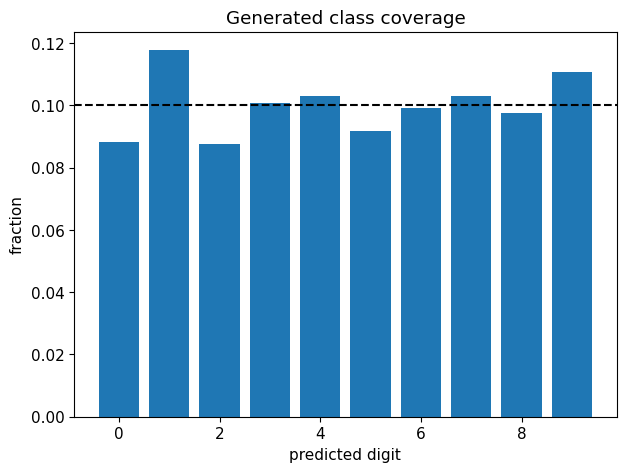

Coverage >1%: 10/10 | entropy: 3.316/3.322 bits | confidence: 95.3%


In [10]:
with torch.no_grad():
    generated = (G_ema(torch.randn(10000, LATENT_DIM, device=DEVICE)) + 1) / 2
    probabilities = classifier(generated).softmax(1)
    predictions = probabilities.argmax(1).cpu()
frequencies = torch.bincount(predictions, minlength=10).float() / len(predictions)
entropy = -(frequencies * torch.log2(frequencies.clamp_min(1e-9))).sum()
confidence = probabilities.max(1).values.mean()
plt.bar(range(10), frequencies)
plt.axhline(0.1, color=PLOT_GUIDE_COLOR, ls="--")
plt.xlabel("predicted digit")
plt.ylabel("fraction")
plt.title("Generated class coverage")
plt.show()
print(
    f"Coverage >1%: {(frequencies>.01).sum().item()}/10 | entropy: {entropy:.3f}/{math.log2(10):.3f} bits | confidence: {confidence:.1%}"
)

>**Expected observation / interpretation.** Yes. A generator can look sharp while overproducing a few classes or near-duplicate styles. Class coverage and feature diversity then fall. The nearest-neighbor check separately asks whether apparent quality comes from memorization.

## 9. Precision, diversity, and memorization proxies

Nearest-neighbor distances test for obvious training-set copying. Pairwise generated distances provide a simple collapse warning. These are transparent teaching diagnostics, not substitutes for comprehensive metrics such as FID or generative precision/recall.

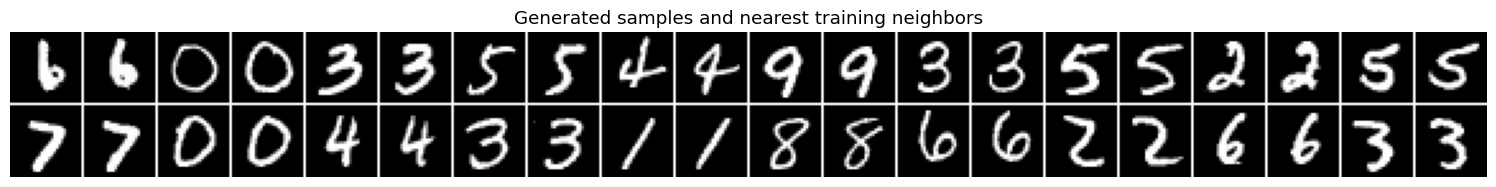

Nearest-neighbor MSE: 0.0250 | normalized pairwise diversity: 0.3673


In [11]:
queries = samples[:20].flatten(1)
training = x_train.flatten(1)
neighbors = []
distances = []
for query in queries:
    best = float("inf")
    best_index = 0
    for start in range(0, len(training), 5000):
        values = (training[start : start + 5000] - query).square().mean(1)
        value, index = values.min(0)
        if value.item() < best:
            best = value.item()
            best_index = start + index.item()
    neighbors.append(x_train[best_index])
    distances.append(best)
pairs = torch.stack([item for pair in zip(samples[:20], neighbors) for item in pair])
show_image_grid(pairs, 20, "Generated samples and nearest training neighbors")
subset = generated[:1000].flatten(1).cpu()
diversity = torch.pdist(subset).mean() / math.sqrt(784)
print(
    f"Nearest-neighbor MSE: {np.mean(distances):.4f} | normalized pairwise diversity: {diversity:.4f}"
)

## 10. What this demonstrates

### Strengths
- sharp, fast, parallel one-pass samples;
- no invertibility or normalized-output constraints on the generator;
- smooth latent manipulation;
- convolutional and residual inductive biases scale naturally to images.

### Costs and limitations
- no normalized likelihood and no direct density evaluation;
- unstable two-player optimization;
- mode dropping can preserve visual quality while losing diversity;
- losses are not reliable standalone quality metrics;
- evaluation requires sample-based proxies and memorization checks.

## Homework experiments


### Mini-experiment 1 — Live versus EMA generator
- **Hypothesis:** EMA weights produce more stable, coherent samples than the live generator near the end of training.
- **Metric/plot:** Show matched-latent grids and compare class entropy, confidence, and pairwise feature diversity.
- **Controls:** Use identical latent vectors, evaluator, sample count, checkpoint step, and preprocessing.
- **Interpretation:** Look for stability gains without silently accepting reduced coverage. 

### Mini-experiment 2 — Spectral-normalization ablation
- **Hypothesis:** Removing spectral normalization makes discriminator updates less controlled and increases instability or collapse risk.
- **Metric/plot:** Plot critic/generator losses, fixed-sample evolution, class entropy, and feature diversity across training.
- **Controls:** Match initialization policy, seed, architecture, augmentation, optimizer, and update ratio.
- **Interpretation:** Do not infer success from losses alone; connect dynamics to coverage and sample trajectories. 

### Extensions
- Replace hinge loss with non-saturating BCE.
- Disable differentiable augmentation.
- Create and save a controlled collapsed checkpoint.
- Add class conditioning.

## Exit ticket

1. Why are GAN losses insufficient as standalone quality metrics?
<details><summary>Self-check</summary>They describe a changing two-player game and need not track perceptual quality, coverage, or memorization monotonically.</details>

2. How can a sharp sample grid still hide mode collapse?
<details><summary>Self-check</summary>A few classes or styles can be rendered sharply while class entropy and feature diversity are low.</details>

3. What distinct questions do coverage and nearest-neighbor diagnostics answer?
<details><summary>Self-check</summary>Coverage asks whether modes/styles are represented. Nearest neighbors probe possible training-set memorization.</details>

## References and further reading

- [Goodfellow et al., “Generative Adversarial Nets” (NeurIPS 2014)](https://proceedings.neurips.cc/paper/2014/hash/f033ed80deb0234979a61f95710dbe25-Abstract.html): Foundational adversarial-learning formulation.
- [Miyato et al., “Spectral Normalization for Generative Adversarial Networks” (ICLR 2018)](https://openreview.net/forum?id=B1QRgziT-): Directly explains the discriminator constraint used for stability here.
- [Official PyTorch DCGAN tutorial](https://pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html): An accessible implementation-oriented comparison point for convolutional GAN training.